## working directory and import libraries

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import cv2
import torch
import ultralytics
from pathlib import Path

PROJECT_ROOT = "/home/user/NeuroVision-AI-2"

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
os.environ["PROJECT_ROOT"] = str(PROJECT_ROOT)
print("Working directory:", os.getcwd())

# import cfgs
from src.config import cfg

#  Quick check
print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("ultralytics :", ultralytics.__version__)
print("opencv      :", cv2.__version__)

print("Raw data :", cfg.RAW_DIR)
print("Classes  :", cfg.CLASS_NAMES)
print("Split    : train %.0f%% / val %.0f%% / test %.0f%%" % (
    (1 - cfg.VAL_RATIO - cfg.TEST_RATIO) * 100, cfg.VAL_RATIO * 100, cfg.TEST_RATIO * 100))
print("Seed     :", cfg.SEED)

Working directory: /home/user/NeuroVision-AI-2
python      : 3.10.22
torch       : 2.14.1+cu130 | CUDA: True
ultralytics : 8.4.192
opencv      : 5.0.0
Raw data : /home/user/NeuroVision-AI-2/data/raw
Classes  : ('Glioma', 'Meningioma', 'No Tumor', 'Pituitary')
Split    : train 70% / val 15% / test 15%
Seed     : 42


## Configuration

In [2]:
from src.config import cfg
from src.mlflow_utils import start_tracking

start_tracking(experiment="neurovision-yolov8")

MLflow tracking: http://localhost:5000 | experiment: neurovision-yolov8 (id 1)


'1'

## Load the champion model

In [6]:
from src.mlflow_utils import compare_runs, pick_champion, register_champion

runs = compare_runs("neurovision-yolov8")
runs

run_id = pick_champion(runs)
register_champion(run_id, model_name="neurovision-yolov8", alias="champion")

2026/10/29 16:50:41 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: neurovision-yolov8, version 1


neurovision-yolov8 version 1 is now 'champion' (run 4da5d7c6)


'1'

In [7]:
from src.evaluate import load_model

model, model_info = load_model(alias="champion", model_name="neurovision-yolov8")
print(model_info)

{'model_name': 'neurovision-yolov8', 'alias': 'champion', 'version': '1', 'run_id': '4da5d7c675d14d458b8508e94f3228f7', 'weights': '/home/user/NeuroVision-AI-2/models/registry/neurovision-yolov8-v1/weights/best.pt', 'run_dir': '/home/user/NeuroVision-AI-2/models/registry/neurovision-yolov8-v1/run_files', 'class_names': ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary'], 'registry_tags': {'recall': '0.9219', 'precision': '0.9406', 'map50': '0.9583', 'map50_95': '0.7253'}}


## Metrics on the test set

In [9]:
from src.evaluate import evaluate

global_metrics, per_class = evaluate(model, data_yaml=cfg.DATA_YAML, split="test")
display(global_metrics)
display(per_class)


Ultralytics 8.4.192 🚀 Python-3.10.22 torch-2.14.1+cu130 CUDA:0 (NVIDIA TITAN RTX, 24023MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1387.6±333.0 MB/s, size: 23.9 KB)
val: Scanning /home/user/NeuroVision-AI-2/data/labels/test... 786 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 786/786 878.9it/s 0.9s0.1s
val: New cache created: /home/user/NeuroVision-AI-2/data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 50/50 11.3it/s 4.4s0.1s
                   all        786        868      0.929      0.924      0.953      0.735
Speed: 0.8ms preprocess, 1.9ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /home/user/NeuroVision-AI-2/runs/evaluation/test


,precision,recall,f1,mAP@0.5,mAP@0.5:0.95,inference_ms_per_image
test,0.9291,0.9237,0.9264,0.953,0.7353,1.8871


,instances,precision,recall,f1,mAP@0.5,mAP@0.5:0.95
class,,,,,,
Glioma,0,0.8514,0.8447,0.8480,0.8816,0.6424
Meningioma,0,0.9708,0.9753,0.9731,0.9863,0.7962
No Tumor,0,1.0000,0.9845,0.9922,0.9950,0.8080
Pituitary,0,0.8943,0.8902,0.8922,0.9489,0.6946


## PR curve, F1 curve and confusion matrix

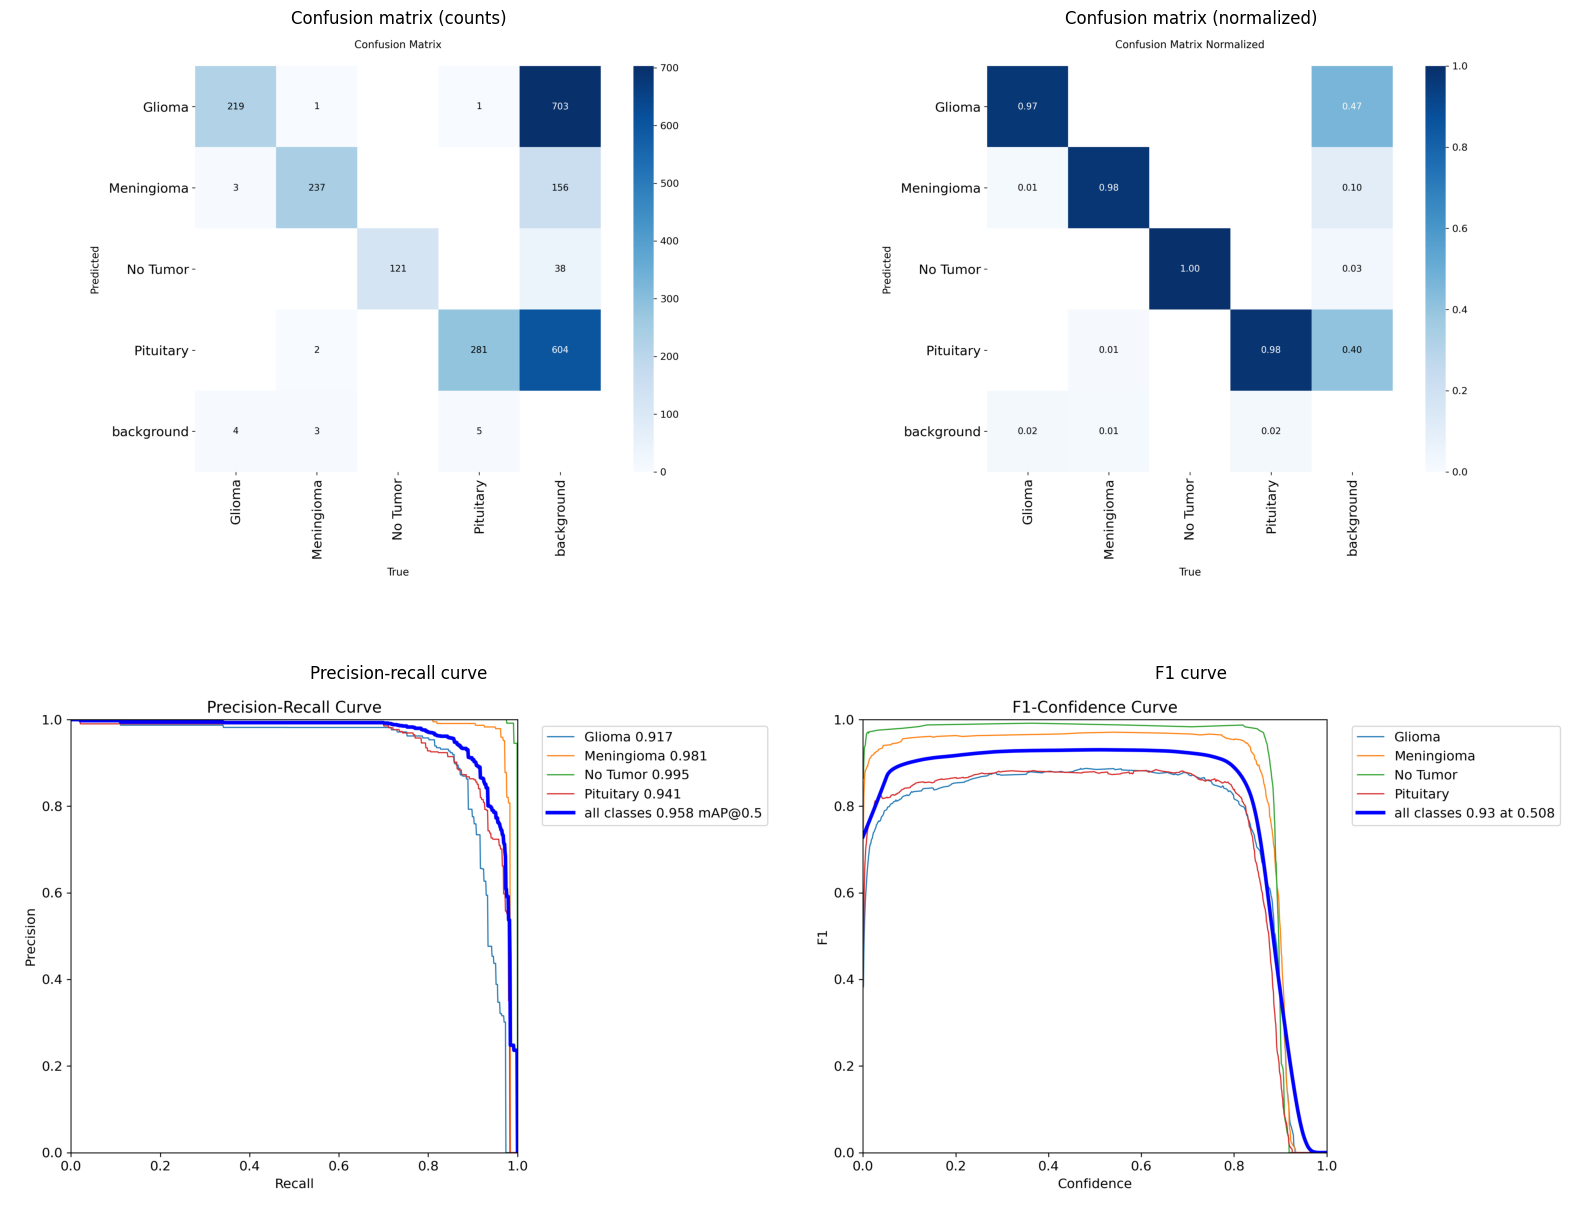

In [11]:
from src.visualization import show_run_plots

show_run_plots(model_info["run_dir"]) # PR_curve, F1_curve, confusion_matrix